# 05 · Chronological validation and model-based value

As Brier (1950) proposed in *Verification of forecasts expressed in terms of probability*, squared probability error provides a forecast-quality measure. Here the sum is taken over the six outcomes of each event. All models are compared on the same later events.

The selected model is the baseline itself, so its difference from the baseline is zero apart from numerical precision. Comparisons with the rejected calibration candidate are supplementary; they are not a new selection step.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


In [2]:
pred=read('outputs/tables/frozen-predictions.json');labels={(x['event'],x['hour']):x['winner'] for x in read('data/processed/outcomes.json')}
test=[e for e in pred if e['phase']=='test' and e['hour']==12]
rows=[]
for e in test:
    y=labels[(e['event'],12)]
    for model,key in [('baseline','p'),('candidate','candidate_p')]:rows.append({'event':e['event'],'date':e['date'],'model':model,**scores(e[key],y)})
df=pd.DataFrame(rows)
show_table(df.groupby('model')[['log_loss','brier']].mean().reset_index(), 'Table N05.1. Independently recomputed held-out noon scores.')
assert len(test)==53
assert len({e['date'] for e in test})==18

model,log_loss,brier
baseline,0.71859,0.40827
candidate,0.72215,0.40935


## Dependence and uncertainty

As Künsch (1989) develops in *The jackknife and the bootstrap for general stationary observations*, resampling neighbouring observations can preserve some serial dependence. The project resamples blocks of calendar-date average paired losses. Cities on a date remain together. Three-day blocks are primary; one- and five-day blocks are sensitivities. Eighteen later dates provide limited support, and weather or source changes can violate stationary approximations.

\overline\Delta=\frac1D\sum_d\frac1{n_d}\sum_{e\in d}(L_e^{model}-L_e^{base}) (17)

mean,lower,upper,dates,draws,block_days
0.00372,-0.00056,0.00877,18,1999,3


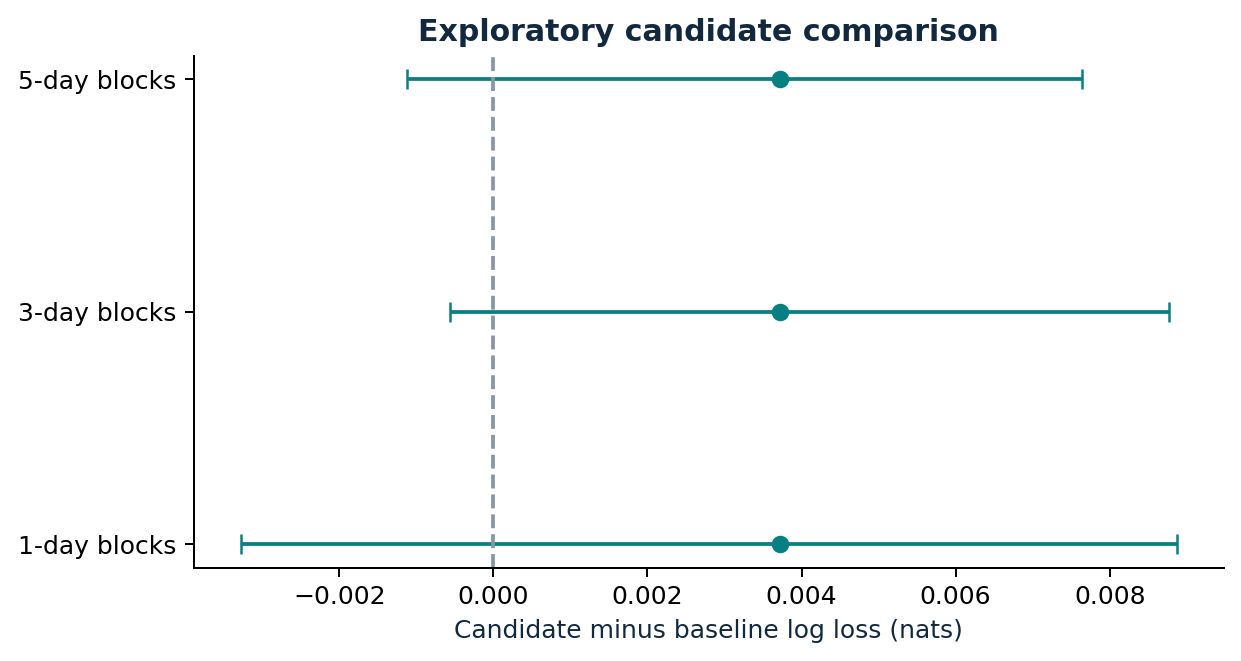

Figure 10. Paired date-block confidence intervals for the rejected candidate on later dates; negative differences favour the candidate. The selected method is the baseline itself.

In [3]:
equation(17)
wide=df.pivot(index=['date','event'],columns='model',values='log_loss')
diffs=(wide.candidate-wide.baseline).groupby(level='date').mean().sort_index()
interval=paired_block_interval(diffs.values,draws=1999,block=3)
show_table(pd.DataFrame([interval]), 'Table N05.2. Paired date-block interval for the rejected candidate, conditional on the frozen fit.')
show_figure(10)

## Expected edge is a different quantity

Equation (16) compares a model probability with acquisition cost. A positive expectation is not a statewise payoff guarantee. The supplementary historical value screen assumes one contract at an hourly ask and a current raw-fee scenario. With no historical depth, queue information or fills, it is not a tradable backtest. The two-cent screen is exploratory and does not determine the primary model selection.

In [4]:
equation(16)
value=read('outputs/probability-results.json')['value_diagnostic']
show_table(pd.DataFrame({'measure':list(value),'value':list(value.values())}), 'Table N05.3. Exploratory candle-ask value diagnostic; no execution claim.')
print('Independent future data are needed before any claim of persistent model-based value.')

\widehat V_i(q)=q\widehat p_i-C_i(q)-F_i(q) (16)

measure,value
events,0
mean_pnl_scenario,None
total_pnl_scenario,0
claims,Not an executable backtest or verified historical fee calculation; exploratory 2-cent screen.


Independent future data are needed before any claim of persistent model-based value.
